# 01 - Binning geometry

Every GammaBayes model evaluates to a cube of **natural-log expected counts** on a regular
`(energy, lon, lat)` grid described by `GammaBinning`.  This notebook covers

* constructing a geometry and what its attributes mean,
* the grids the components receive (`shaped_grid`, `axes_mesh`),
* bin volumes,
* edges are given with `from_edges`, padded *true-space* copies with `padded`, and equality.

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple MPS: run the few unsupported ops on the CPU
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"
# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64, so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_default_dtype(torch.float32 if device == "mps" else torch.float64)   # float64 where available: exactness over speed
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning
npy = lambda t: t.detach().cpu().numpy()

torch 2.15.0 on mps (torch.float32), FAST=False


[wall time: 2.3 s]


## Constructing a geometry

Resolutions are **bins per unit**: `energy_res` bins per decade (the energy axis is log-uniform),
`lon_res` / `lat_res` bins per degree.  Energies are in TeV, angles in Galactic degrees.

In [2]:
geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100.,
                    lon_res=10, lon_min=-3., lon_max=3.,
                    lat_res=10, lat_min=-3., lat_max=3.)
print(geom)
print("shape (E, lon, lat):", geom.shape)
print("energy axis [TeV]  :", npy(geom.energy_axis)[:4], "...", npy(geom.energy_axis)[-2:])
print("lon axis [deg]     :", npy(geom.lon_axis)[:3], "...", npy(geom.lon_axis)[-2:])

GammaBinning(E: 30 bins 0.1-100 TeV, lon: 60 bins -3..3 deg, lat: 60 bins -3..3 deg)
shape (E, lon, lat): (30, 60, 60)
energy axis [TeV]  : [0.11220184 0.14125374 0.17782788 0.22387204] ... [70.794586 89.12511 ]
lon axis [deg]     : [-2.95 -2.85 -2.75] ... [2.85 2.95]


[wall time: 237 ms]


`energy_axis`, `lon_axis`, `lat_axis` are the **bin centres** (log-centre for energy);
`energy_edges`, `lon_edges`, `lat_edges` are the edges.  `num_energy_bins`,
`num_lon_bins`, `num_lat_bins` are historical names for the number of **edges**
(`bins + 1`); use `geom.shape` for the number of bins.

In [3]:
print("edges:", len(geom.energy_edges), len(geom.lon_edges), len(geom.lat_edges))
print("num_*_bins (edge counts!):", geom.num_energy_bins, geom.num_lon_bins, geom.num_lat_bins)
print("log10 step [dex]:", float(torch.log10(geom.energy_edges[1]) - torch.log10(geom.energy_edges[0])))
print("pixel [deg]     :", float(geom.lon_edges[1] - geom.lon_edges[0]))

edges: 31 61 61
num_*_bins (edge counts!): 31 61 61
log10 step [dex]: 0.10000002384185791
pixel [deg]     : 0.09999990463256836


[wall time: 3 ms]


## Grids handed to the components

* `shaped_grid` is `(E, lon, lat, 3)` with the bin-centre coordinates of every voxel.
  `TwoCompFluxPrior` slices it into the energy axis `grid[..., 0, 0, 0]` and the sky grid
  `grid[0, ..., 1:]` of shape `(lon, lat, 2)` that spatial components receive.
* `axes_mesh` is the same information as a `(3, E, lon, lat)` stack, convenient for IRF calls.
* `grid` is the flattened `(E*lon*lat, 3)` version.

In [4]:
g = geom.shaped_grid
print("shaped_grid:", tuple(g.shape))
print("energy axis from grid == energy_axis:", torch.equal(g[..., 0, 0, 0], geom.energy_axis))
lonlat = g[0, ..., 1:]
print("sky grid (lon, lat, 2):", tuple(lonlat.shape), "  first pixel:", npy(lonlat[0, 0]), " last:", npy(lonlat[-1, -1]))
print("axes_mesh:", tuple(geom.axes_mesh.shape), "  flat grid:", tuple(geom.grid.shape))

shaped_grid: (30, 60, 60, 3)
energy axis from grid == energy_axis: True
sky grid (lon, lat, 2): (60, 60, 2)   first pixel: [-2.95 -2.95]  last: [2.95 2.95]
axes_mesh: (3, 30, 60, 60)   flat grid: (108000, 3)


[wall time: 11 ms]


## Bin volumes

`bin_width_mat` is `dE[:, None, None] * dlon[None, :, None] * dlat[None, None, :]`
(TeV deg²): turns a differential flux density into counts once multiplied by
the exposure.  It is a flat-sky product (no `cos(b)`), which is accurate to < 0.2 % inside
|b| < 3°.

bin_width_mat: (30, 60, 60)  total volume [TeV deg^2] = 3596.39990234375


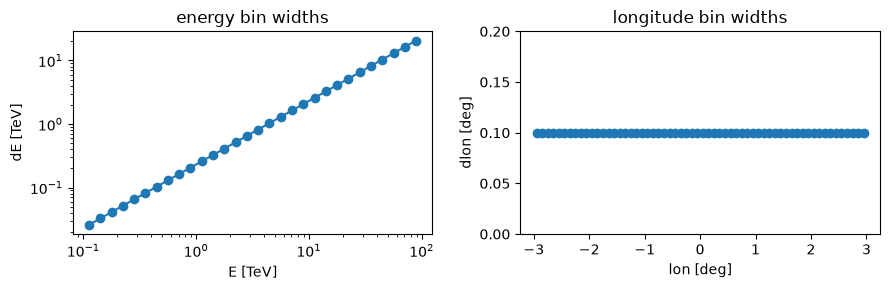

[wall time: 374 ms]


In [5]:
V = geom.bin_width_mat
print("bin_width_mat:", tuple(V.shape), " total volume [TeV deg^2] =", float(V.sum()))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].loglog(npy(geom.energy_axis), npy(geom.energy_bin_widths), "o-")
ax[0].set(xlabel="E [TeV]", ylabel="dE [TeV]", title="energy bin widths")
ax[1].plot(npy(geom.lon_axis), npy(geom.lon_bin_widths), "o-")
ax[1].set(xlabel="lon [deg]", ylabel="dlon [deg]", title="longitude bin widths", ylim=(0, 0.2))
plt.tight_layout()

## Exact edges: `from_edges`

The constructor computes `int(range * res + 1)` edges, which truncates when the floating-point
product lands just below an integer: a 5.2-degree window at 10 bins/deg gives 52 edges (instead of 53).  When the grid must be exactly as specified (padding another geometry, matching a template),
build it from edges.

In [6]:
# (-4.1 - 1.1) deg at 10 bins/deg: 5.2 * 10 + 1 = 52.99999... -> int() gives 52 edges, i.e. 51 bins instead of 52
bad = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100., lon_res=10, lon_min=-4.1, lon_max=1.1, lat_res=10, lat_min=-1., lat_max=1.)
print("5.2 deg at 10 bins/deg from the constructor ->", bad.shape[1], "lon bins   (expected 52)")

exact = GammaBinning.from_edges(energy_edges=torch.logspace(-1, 2, 31),
                                lon_edges=torch.linspace(-4.1, 1.1, 53), lat_edges=torch.linspace(-1., 1., 21))
print("from_edges                                 ->", exact.shape[1], "lon bins")

5.2 deg at 10 bins/deg from the constructor -> 52 lon bins   (expected 52)
from_edges                                 -> 52 lon bins


[wall time: 10 ms]


## Padded true-space geometries

The instrument response moves events across bins, so the **true** cube that the forward
operator consumes must extend beyond the analysis window by the kernel half-width on every
side (`IRFForwardConv.pads`).  `padded(pads)` returns that geometry; its interior edges are the
original edges exactly, so a "valid" convolution over the padded cube lands on `geom`.

In [7]:
tg = geom.padded((2, 3, 3))          # 2 energy bins, 3 pixels on every side
print("reco:", geom.shape, " true:", tg.shape)
print("true energy range: %.3g - %.3g TeV (reco %.3g - %.3g)" % (tg.energy_edges[0], tg.energy_edges[-1], geom.energy_edges[0], geom.energy_edges[-1]))
inner = tg.lon_edges[3:3 + len(geom.lon_edges)]
print("interior lon edges identical:", torch.allclose(inner, geom.lon_edges))

reco: (30, 60, 60)  true: (34, 66, 66)
true energy range: 0.0631 - 158 TeV (reco 0.1 - 100)
interior lon edges identical: True


[wall time: 8 ms]


## Equality

Two geometries compare equal when their edges agree (to 1e-6 relative).  Exposures and priors
check this before being combined.

In [8]:
same = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100., lon_res=10, lon_min=-3., lon_max=3., lat_res=10, lat_min=-3., lat_max=3.)
print("geom == same:", geom == same, "   geom == padded:", geom == tg)

geom == same: True    geom == padded: False


[wall time: 9 ms]


## Devices and precision

Geometries are built on `torch.get_default_device()` with `torch.get_default_dtype()`.  Set both
*before* constructing anything (as in the setup cell) and every model built on the geometry
inherits them.  Use `float64` for reference runs; `float32` is ~2x faster on data-centre GPUs
and accurate to a few 1e-2 nats in the likelihood for GC-sized problems.

In [9]:
print("axis device/dtype:", geom.energy_axis.device, geom.energy_axis.dtype)

axis device/dtype: mps:0 torch.float32


[wall time: 2 ms]
